# Demo Thực Nghiệm Chương 3: Ứng Dụng Thuật Toán CHARM (Group_12_Charm)

**Môn học:** Khai phá Dữ liệu (Data Mining) — Khoa CNTT, Trường ĐH Khoa học Tự nhiên, ĐHQG-HCM (FIT-HCMUS)  
**Nhóm thực hiện:** Nhóm 12 (`Group_12_Charm`)  
**Repository:** [`khoagiap1312/Group_12_Charm`](https://github.com/khoagiap1312/Group_12_Charm)  
**Kho dữ liệu Hugging Face:** [`Quanbro7/Charm_Dataset`](https://huggingface.co/datasets/Quanbro7/Charm_Dataset)

---

### Mục tiêu & Luồng thực thi của Notebook
Notebook này gọi **trực tiếp các kịch bản chính thức trong repo của nhóm**:

1. **Phần 1 — Thiết lập môi trường:** Cài đặt **Julia 1.13.4** (khớp `Manifest.toml`), clone repo `Group_12_Charm`, cài thư viện Python cần thiết và khởi tạo `Project.toml`.
2. **Phần 2 — Tải dữ liệu thực tế:** Tải trực tiếp dữ liệu tiền xử lý của 2 ứng dụng từ `Quanbro7/Charm_Dataset` vào `data/application/...`.
3. **Phần 3 — Ứng dụng 1 (Web Server Access Logs):** Gọi `src/main.jl`, `scripts/invert_parse.jl` (giải mã nhãn sự kiện) và `scripts/analyze_web_logs.py` (thống kê, so sánh Normal vs. Anomalous và vẽ biểu đồ).
4. **Phần 4 — Ứng dụng 2 (Caltech-101 Visual Patterns):** Gọi `scripts/analyze_caltech101.py --split-classes`, chạy `src/main.jl` cho toàn tập và 3 lớp riêng, sau đó gọi `scripts/analyze_caltech101.py` để tính Class Purity và vẽ lưới patch 3×3.
5. **Phần 5 — Kiểm tra tổng hợp đầu ra:** Xác minh toàn bộ tệp CSV và hình PNG đã được tạo đầy đủ.

## Phần 1. Thiết lập môi trường trên Google Colab (Julia + Python + Mã nguồn)

### 1.1. Cấu hình tham số tái lập và hàm chạy lệnh có in chi tiết lỗi
Hàm `run_cmd` được dùng xuyên suốt notebook: nếu bất kỳ script Julia/Python nào gặp sự cố, notebook sẽ in rõ câu lệnh, mã lỗi (`returncode`), `STDOUT` và `STDERR` rồi dừng ngay để dễ kiểm tra.

In [1]:
import os
import random
import subprocess
import sys
import time
from pathlib import Path
from google.colab import output
output.enable_custom_widget_manager()

import numpy as np

# CẤU HÌNH CHUNG (CỐ ĐỊNH SEED = 0)
SEED = 0
random.seed(SEED)
np.random.seed(SEED)

GITHUB_REPO_URL = "https://github.com/khoagiap1312/Group_12_Charm.git"
REPO_DIR_NAME = "Group_12_Charm"
HF_DATASET_REPO = "Quanbro7/Charm_Dataset"

# JULIA VERSION
JULIA_VERSION = "1.13.4"
JULIA_MAJOR_MINOR = "1.13"


def run_cmd(cmd: list[str], desc: str = "") -> subprocess.CompletedProcess:
    '''Chạy lệnh hệ thống; in đầy đủ STDOUT/STDERR và dừng ngay nếu xảy ra lỗi.'''
    t0 = time.perf_counter()
    proc = subprocess.run(cmd, capture_output=True, text=True)
    dt = time.perf_counter() - t0
    if proc.returncode != 0:
        print(f"[ERROR] Thất bại khi thực thi ({desc or 'command'}) — Exit code: {proc.returncode}")
        print(f"  Command: {' '.join(cmd)}")
        if proc.stdout.strip():
            print("  --- STDOUT ---\n" + proc.stdout.strip())
        if proc.stderr.strip():
            print("  --- STDERR ---\n" + proc.stderr.strip())
        raise RuntimeError(f"Lệnh thất bại (exit code {proc.returncode}): {' '.join(cmd)}")
    if desc:
        print(f"[OK] {desc} ({dt:.2f}s)")
    return proc


print(f"Python version : {sys.version.split()[0]}")
print(f"Fixed SEED     : {SEED}")
print(f"GitHub Repo    : {GITHUB_REPO_URL}")
print(f"HF Dataset Repo: {HF_DATASET_REPO}")

Python version : 3.13.18
Fixed SEED     : 0
GitHub Repo    : https://github.com/khoagiap1312/Group_12_Charm.git
HF Dataset Repo: Quanbro7/Charm_Dataset


### 1.2. Tự động tải và cài đặt Julia 1.13.4 trên Google Colab
Ô lệnh kiểm tra xem `julia` đã có sẵn chưa; nếu chưa, tự tải bản nhị phân chính thức **Julia 1.13.4 (Linux x86_64)** để khớp hoàn toàn với `Manifest.toml` của nhóm.

In [2]:
%%bash -s "$JULIA_VERSION" "$JULIA_MAJOR_MINOR"
set -euo pipefail
JULIA_VER=$1
JULIA_MM=$2

if command -v julia >/dev/null 2>&1; then
    echo "[OK] Julia đã được cài đặt sẵn:"
    julia --version
else
    echo "[INFO] Đang tải Julia ${JULIA_VER} cho Linux x86_64..."
    URL="https://julialang-s3.julialang.org/bin/linux/x64/${JULIA_MM}/julia-${JULIA_VER}-linux-x86_64.tar.gz"
    wget -q --show-progress -O /tmp/julia.tar.gz "${URL}"
    mkdir -p /usr/local/julia
    tar -xzf /tmp/julia.tar.gz -C /usr/local/julia --strip-components=1
    ln -sf /usr/local/julia/bin/julia /usr/local/bin/julia
    rm -f /tmp/julia.tar.gz
    echo "[OK] Cài đặt hoàn tất:"
    julia --version
fi

[OK] Julia đã được cài đặt sẵn:
julia version 1.12.6


### 1.3. Clone mã nguồn `Group_12_Charm` và cài đặt môi trường
- Cài các thư viện Python dùng trong `scripts/ và tải dữ liệu Hugging Face.
- Clone repo `Group_12_Charm` (hoặc dùng thư mục hiện tại nếu đang chạy trong repo).
- Khởi tạo gói Julia theo `Project.toml` / `Manifest.toml` (đặt `JULIA_CONDAPKG_BACKEND=Null` để không kéo thêm Conda phụ trên Colab) và kiểm tra CLI `src/main.jl`.

In [3]:
import shutil

# 1. Cài đặt thư viện Python cần thiết cho các script trong repo
run_cmd(
    [
        sys.executable, "-m", "pip", "install", "-q",
        "huggingface_hub", "pandas", "numpy", "matplotlib", "pillow", "ipywidgets",
    ],
    desc="Cài đặt thư viện Python",
)

# 2. Nếu chạy trên Google Colab: thoát về /content, xóa bản cũ và clone mới nhất từ main
if Path("/content").exists():
    os.chdir("/content")
    repo_dir = Path("/content") / REPO_DIR_NAME
    if repo_dir.exists():
        shutil.rmtree(repo_dir)
    run_cmd(
        ["git", "clone", "--depth", "1", GITHUB_REPO_URL, str(repo_dir)],
        desc="Clone repo Group_12_Charm (main)",
    )
    PROJECT_ROOT = repo_dir
else:
    cwd = Path.cwd()
    PROJECT_ROOT = cwd if (cwd / "src" / "main.jl").exists() else cwd.parent

os.chdir(PROJECT_ROOT)
print(f"[OK] Thư mục làm việc hiện tại: {Path.cwd()}")

# 3. Khởi tạo môi trường Julia theo Project.toml / Manifest.toml
os.environ["JULIA_CONDAPKG_BACKEND"] = "Null"
assert (PROJECT_ROOT / "Project.toml").exists(), "Không tìm thấy Project.toml trong thư mục gốc repo!"
run_cmd(
    ["julia", "--project=.", "-e", "using Pkg; Pkg.instantiate()"],
    desc="Khởi tạo môi trường Julia (Pkg.instantiate)",
)

# 4. Kiểm tra các script chính thức cần gọi trong repo
required_scripts = [
    "src/main.jl",
    "scripts/invert_parse.jl",
    "scripts/analyze_web_logs.py",
    "scripts/analyze_caltech101.py",
]
for s in required_scripts:
    assert Path(s).exists(), f"Thiếu script bắt buộc trong repo: {s}"

res_help = run_cmd(["julia", "--project=.", "src/main.jl", "--help"], desc="Kiểm tra CLI src/main.jl")
print(res_help.stdout)

[OK] Cài đặt thư viện Python (11.78s)
[OK] Clone repo Group_12_Charm (main) (0.75s)
[OK] Thư mục làm việc hiện tại: /content/Group_12_Charm
[OK] Khởi tạo môi trường Julia (Pkg.instantiate) (5.10s)
[OK] Kiểm tra CLI src/main.jl (3.42s)
CHARM Frequent Closed Itemset Mining - CLI

Usage:
  julia src/main.jl --input <path> --minsup <threshold> [--output <path>] [--algo <name>]

Options:
  -i, --input <path>        Path to input transaction file (SPMF .txt format) [Required]
  -m, --minsup <threshold>  Minimum support [Required]. Supports 3 formats:
                              • Percentage (SPMF-style): e.g. "40%", "33.3%" (0% < m <= 100%)
                              • Relative fraction:       e.g. 0.4, 0.33 (0.0 < m <= 1.0)
                              • Absolute count:          e.g. 3, 10 (integer >= 1)
  -o, --output <path>       Path to output file (default: "output.txt")
  -a, --algo <name>         Solver implementation: "baseline" or "optimized" (default: "baseline")
  -w, --warm

## Phần 2. Tải dữ liệu thực tế từ Hugging Face (`Quanbro7/Charm_Dataset`)

Tải trực tiếp các tệp đã tiền xử lý của hai ứng dụng về đúng thư mục mà `scripts/analyze_web_logs.py` và `scripts/analyze_caltech101.py` yêu cầu:
- `data/application/web_server_access_logs/pre_process/` (`transaction.txt`, `mapping.csv`)
- `data/application/cal_tech_101/pre_process/` (`transactions.txt`, `image_mapping.csv`, `visual_word_stats.csv`, `patches/word_*.png`)


In [4]:
import shutil
import pandas as pd
from huggingface_hub import HfApi, snapshot_download

WEB_PRE_DIR = Path("data/application/web_server_access_logs/pre_process")
CALTECH_PRE_DIR = Path("data/application/cal_tech_101/pre_process")
WEB_PRE_DIR.mkdir(parents=True, exist_ok=True)
CALTECH_PRE_DIR.mkdir(parents=True, exist_ok=True)

api = HfApi()
hf_files = api.list_repo_files(repo_id=HF_DATASET_REPO, repo_type="dataset")
print(f"[OK] Kết nối Hugging Face dataset '{HF_DATASET_REPO}' ({len(hf_files)} tệp).")


def download_hf_dataset_dir(keyword: str, local_dir: Path, required_files: list[str]) -> None:
    '''Tải đúng thư mục dữ liệu tiền xử lý từ Hugging Face về local_dir; báo lỗi ngay nếu thiếu.'''
    if all((local_dir / f).exists() for f in required_files):
        print(f"[OK] Dữ liệu đã có sẵn tại {local_dir}")
        return

    anchor_hits = [
        f for f in hf_files
        if keyword in f.lower() and Path(f).name == required_files[0]
    ]
    if not anchor_hits:
        raise FileNotFoundError(
            f"Không tìm thấy '{required_files[0]}' (từ khóa '{keyword}') trên Hugging Face repo '{HF_DATASET_REPO}'."
        )

    prefix = str(Path(anchor_hits[0]).parent)
    allow_patterns = [f"{prefix}/*"] if prefix != "." else required_files
    print(f"[INFO] Đang tải '{prefix}' từ {HF_DATASET_REPO} -> {local_dir} ...")

    snap_dir = Path(
        snapshot_download(
            repo_id=HF_DATASET_REPO,
            repo_type="dataset",
            allow_patterns=allow_patterns,
        )
    )
    src_root = snap_dir / prefix if prefix != "." else snap_dir
    for item in src_root.rglob("*"):
        if item.is_file():
            dst = local_dir / item.relative_to(src_root)
            dst.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(item, dst)

    missing = [f for f in required_files if not (local_dir / f).exists()]
    if missing:
        raise FileNotFoundError(f"Thiếu tệp bắt buộc sau khi tải về {local_dir}: {missing}")
    print(f"[OK] Đã tải đủ dữ liệu về {local_dir}")


# 1. Tải dữ liệu Ứng dụng 1: Web Server Access Logs
download_hf_dataset_dir(
    keyword="web",
    local_dir=WEB_PRE_DIR,
    required_files=["transaction.txt", "mapping.csv"],
)

# 2. Tải dữ liệu Ứng dụng 2: Caltech-101
download_hf_dataset_dir(
    keyword="cal",
    local_dir=CALTECH_PRE_DIR,
    required_files=["transactions.txt", "image_mapping.csv", "visual_word_stats.csv"],
)

patch_files = list((CALTECH_PRE_DIR / "patches").glob("word_*.png"))
if not patch_files:
    raise FileNotFoundError(
        f"Không tìm thấy ảnh patch trong {CALTECH_PRE_DIR / 'patches'}. "
        "Kiểm tra lại thư mục patches/ trên Hugging Face."
    )
print(f"[OK] Đã tìm thấy {len(patch_files)} ảnh lưới patch đại diện tại {CALTECH_PRE_DIR / 'patches'}")

[OK] Kết nối Hugging Face dataset 'Quanbro7/Charm_Dataset' (948 tệp).
[INFO] Đang tải 'application/web_server_access_logs/pre_process' từ Quanbro7/Charm_Dataset -> data/application/web_server_access_logs/pre_process ...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

[OK] Đã tải đủ dữ liệu về data/application/web_server_access_logs/pre_process
[INFO] Đang tải 'application/cal_tech_101/pre_process' từ Quanbro7/Charm_Dataset -> data/application/cal_tech_101/pre_process ...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 304 files:   0%|          | 0/304 [00:00<?, ?it/s]

[OK] Đã tải đủ dữ liệu về data/application/cal_tech_101/pre_process
[OK] Đã tìm thấy 300 ảnh lưới patch đại diện tại data/application/cal_tech_101/pre_process/patches


---
## Phần 3. Ứng dụng 1: Khai phá mẫu hành vi và phát hiện bất thường trên Web Server Access Logs

### Quy trình gọi trực tiếp các script trong repo
1. `julia --project=. src/main.jl -a optimized`: Khai phá Closed Frequent Itemsets trên **520.428 phiên truy cập** ở 5 mức `minsup ∈ {0.1, 0.05, 0.02, 0.01, 0.005}`.
2. `julia --project=. scripts/invert_parse.jl`: Giải mã kết quả SPMF sang tên nhãn sự kiện (`mapping.csv`) tại `minsup = 0.01` và `0.005`.
3. `python scripts/analyze_web_logs.py`: Tổng hợp `minsup_summary.csv`, đối chiếu Normal vs. Anomalous (`normal_vs_anomaly_comparison.csv`) và vẽ 2 biểu đồ.

In [5]:
WEB_OUT_DIR = Path("results/application/web_server_access_logs")
WEB_OUT_DIR.mkdir(parents=True, exist_ok=True)

WEB_MINSUPS = ["0.1", "0.05", "0.02", "0.01", "0.005"]

print("=== Bước 3.1: Chạy CHARM tối ưu (src/main.jl) trên Web Server Access Logs ===")
for ms in WEB_MINSUPS:
    out_file = WEB_OUT_DIR / f"charm_minsup_{ms}.txt"
    res = run_cmd(
        [
            "julia", "--project=.", "src/main.jl",
            "-i", str(WEB_PRE_DIR / "transaction.txt"),
            "-m", ms,
            "-o", str(out_file),
            "-a", "optimized",
        ],
        desc=f"CHARM Web Logs minsup={ms}",
    )
    print(" ", res.stdout.strip())

=== Bước 3.1: Chạy CHARM tối ưu (src/main.jl) trên Web Server Access Logs ===
[OK] CHARM Web Logs minsup=0.1 (10.26s)
  [OptimizedCharmSolver] Transactions: 520428 | MinSup Count: 52043 | Closed Itemsets: 179 | Read: 4257.47 ms | Time: 411.86 ms | Write: 18.38 ms | Total: 4687.7 ms | PeakRSS: 518.6 MB
[OK] CHARM Web Logs minsup=0.05 (6.68s)
  [OptimizedCharmSolver] Transactions: 520428 | MinSup Count: 26022 | Closed Itemsets: 590 | Read: 2062.5 ms | Time: 573.77 ms | Write: 11.68 ms | Total: 2647.95 ms | PeakRSS: 533.7 MB
[OK] CHARM Web Logs minsup=0.02 (5.76s)
  [OptimizedCharmSolver] Transactions: 520428 | MinSup Count: 10409 | Closed Itemsets: 1816 | Read: 2108.3 ms | Time: 661.54 ms | Write: 14.64 ms | Total: 2784.49 ms | PeakRSS: 542.1 MB
[OK] CHARM Web Logs minsup=0.01 (7.28s)
  [OptimizedCharmSolver] Transactions: 520428 | MinSup Count: 5205 | Closed Itemsets: 4210 | Read: 2040.19 ms | Time: 1137.69 ms | Write: 18.45 ms | Total: 3196.33 ms | PeakRSS: 542.5 MB
[OK] CHARM Web Logs

In [6]:
print("=== Bước 3.2: Giải mã SPMF sang Event Templates bằng scripts/invert_parse.jl ===")
for ms in ["0.01", "0.005"]:
    spmf_in = WEB_OUT_DIR / f"charm_minsup_{ms}.txt"
    decoded_out = WEB_OUT_DIR / f"decoded_minsup_{ms}.txt"
    res = run_cmd(
        [
            "julia", "--project=.", "scripts/invert_parse.jl",
            "--spmf", str(spmf_in),
            "--map", str(WEB_PRE_DIR / "mapping.csv"),
            "--output", str(decoded_out),
        ],
        desc=f"invert_parse.jl minsup={ms}",
    )
    print(" ", res.stdout.strip())

print("\nMẫu 5 dòng đầu trong decoded_minsup_0.005.txt:")
with open(WEB_OUT_DIR / "decoded_minsup_0.005.txt", "r", encoding="utf-8") as f:
    for _ in range(5):
        print(" ", f.readline().strip())

=== Bước 3.2: Giải mã SPMF sang Event Templates bằng scripts/invert_parse.jl ===
[OK] invert_parse.jl minsup=0.01 (10.11s)
  Đang xử lý và ghi file...
DONE! File output tại: results/application/web_server_access_logs/decoded_minsup_0.01.txt
[OK] invert_parse.jl minsup=0.005 (11.10s)
  Đang xử lý và ghi file...
DONE! File output tại: results/application/web_server_access_logs/decoded_minsup_0.005.txt

Mẫu 5 dòng đầu trong decoded_minsup_0.005.txt:
  GET_PRODUCT_301 #SUP: 2792
  GET_SETTINGS_200 REF_LINKED GET_IMAGE_200 BEHAVIOR_NORMAL_ASSET_LOAD GET_SITE_302 #SUP: 2872
  GET_SETTINGS_200 REF_LINKED BEHAVIOR_NORMAL_ASSET_LOAD GET_SITE_302 #SUP: 3009
  GET_SETTINGS_200 BEHAVIOR_NORMAL_ASSET_LOAD GET_SITE_302 #SUP: 3010
  REF_LINKED GET_IMAGE_200 BEHAVIOR_NORMAL_ASSET_LOAD GET_SITE_302 #SUP: 2904


=== Bước 3.3: Phân tích & vẽ biểu đồ bằng scripts/analyze_web_logs.py ===
[OK] analyze_web_logs.py (7.95s)
Đã nạp 345 items từ data/application/web_server_access_logs/pre_process/mapping.csv (139 item gắn cờ bất thường/bot/lỗi).

=== 1. TỔNG HỢP KẾT QUẢ CHARM THEO CÁC MỨC MINSUP ===
 minsup  minsup_count  total_closed  closed_len_ge_2  max_length                   file
  0.100         52043           179              162           6   charm_minsup_0.1.txt
  0.050         26022           590              572           8  charm_minsup_0.05.txt
  0.020         10409          1816             1788          10  charm_minsup_0.02.txt
  0.010          5205          4210             4173          11  charm_minsup_0.01.txt
  0.005          2603          7839             7791          12 charm_minsup_0.005.txt

=== 2. TOP 15 CLOSED ITEMSETS (len >= 2) TẠI minsup = 0.005 ===
 1. [sup=248,205 | 47.69% | len=2] GET_IMAGE_200 + UA_MOBILE
 2. [sup=229,108 | 44.02% | len=2] GET_IMAGE_200 + REF_LINKED


,minsup,minsup_count,total_closed,closed_len_ge_2,max_length,file
0,0.100,52043,179,162,6,charm_minsup_0.1.txt
1,0.050,26022,590,572,8,charm_minsup_0.05.txt
2,0.020,10409,1816,1788,10,charm_minsup_0.02.txt
3,0.010,5205,4210,4173,11,charm_minsup_0.01.txt
4,0.005,2603,7839,7791,12,charm_minsup_0.005.txt



=== Top 10 Closed Itemsets đặc trưng mạnh cho phiên Bất thường / Bot / Scan (Ratio >= 1.5) ===


,length,sup_all_pct,sup_normal_pct,sup_anomaly_pct,anom_to_norm_ratio,event_templates
30,2,15.600,0.000,52.984,999.0,REF_DIRECT + UA_KNOWN_BOT
31,2,14.260,0.000,48.433,999.0,BEHAVIOR_NO_ASSET_SCRAPING + REF_DIRECT
32,2,13.312,0.000,45.215,999.0,BEHAVIOR_NO_ASSET_SCRAPING + UA_KNOWN_BOT
18,2,25.829,19.511,40.970,2.1,RATE_SINGLE + REF_DIRECT
33,2,11.963,0.000,40.633,999.0,BEHAVIOR_NO_ASSET_SCRAPING + RATE_SINGLE
34,3,11.896,0.000,40.405,999.0,BEHAVIOR_NO_ASSET_SCRAPING + REF_DIRECT + UA_K...
35,2,11.446,0.000,38.874,999.0,RATE_SINGLE + UA_KNOWN_BOT
36,3,11.159,0.000,37.899,999.0,RATE_SINGLE + REF_DIRECT + UA_KNOWN_BOT
37,3,10.795,0.000,36.665,999.0,BEHAVIOR_NO_ASSET_SCRAPING + RATE_SINGLE + REF...
38,3,10.267,0.000,34.872,999.0,BEHAVIOR_NO_ASSET_SCRAPING + RATE_SINGLE + UA_...



--- fig1_minsup_vs_itemsets.png ---


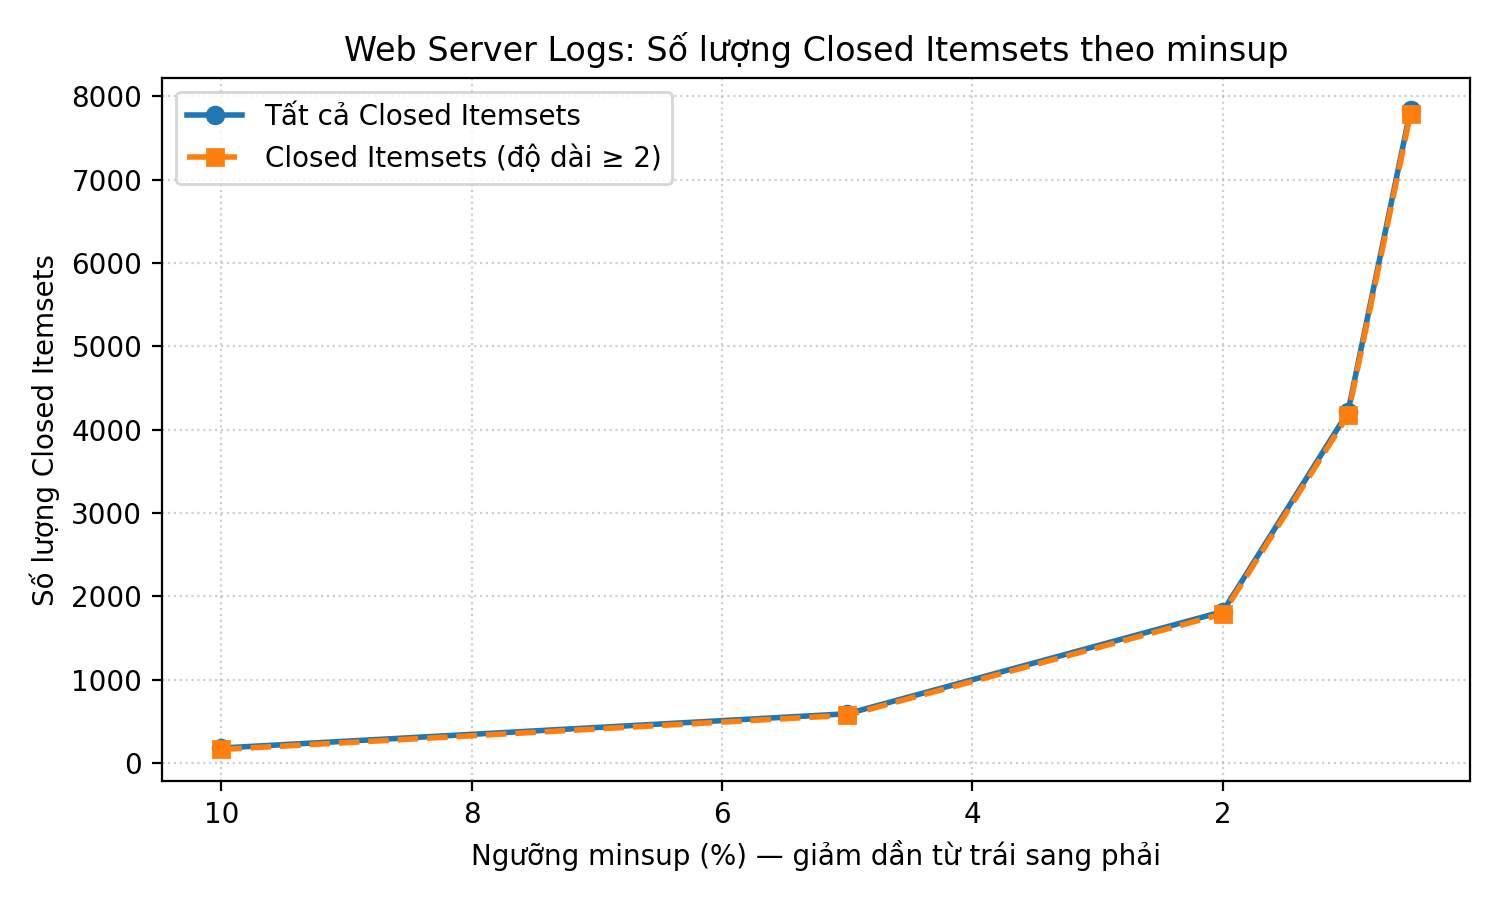


--- fig2_normal_vs_anomaly.png ---


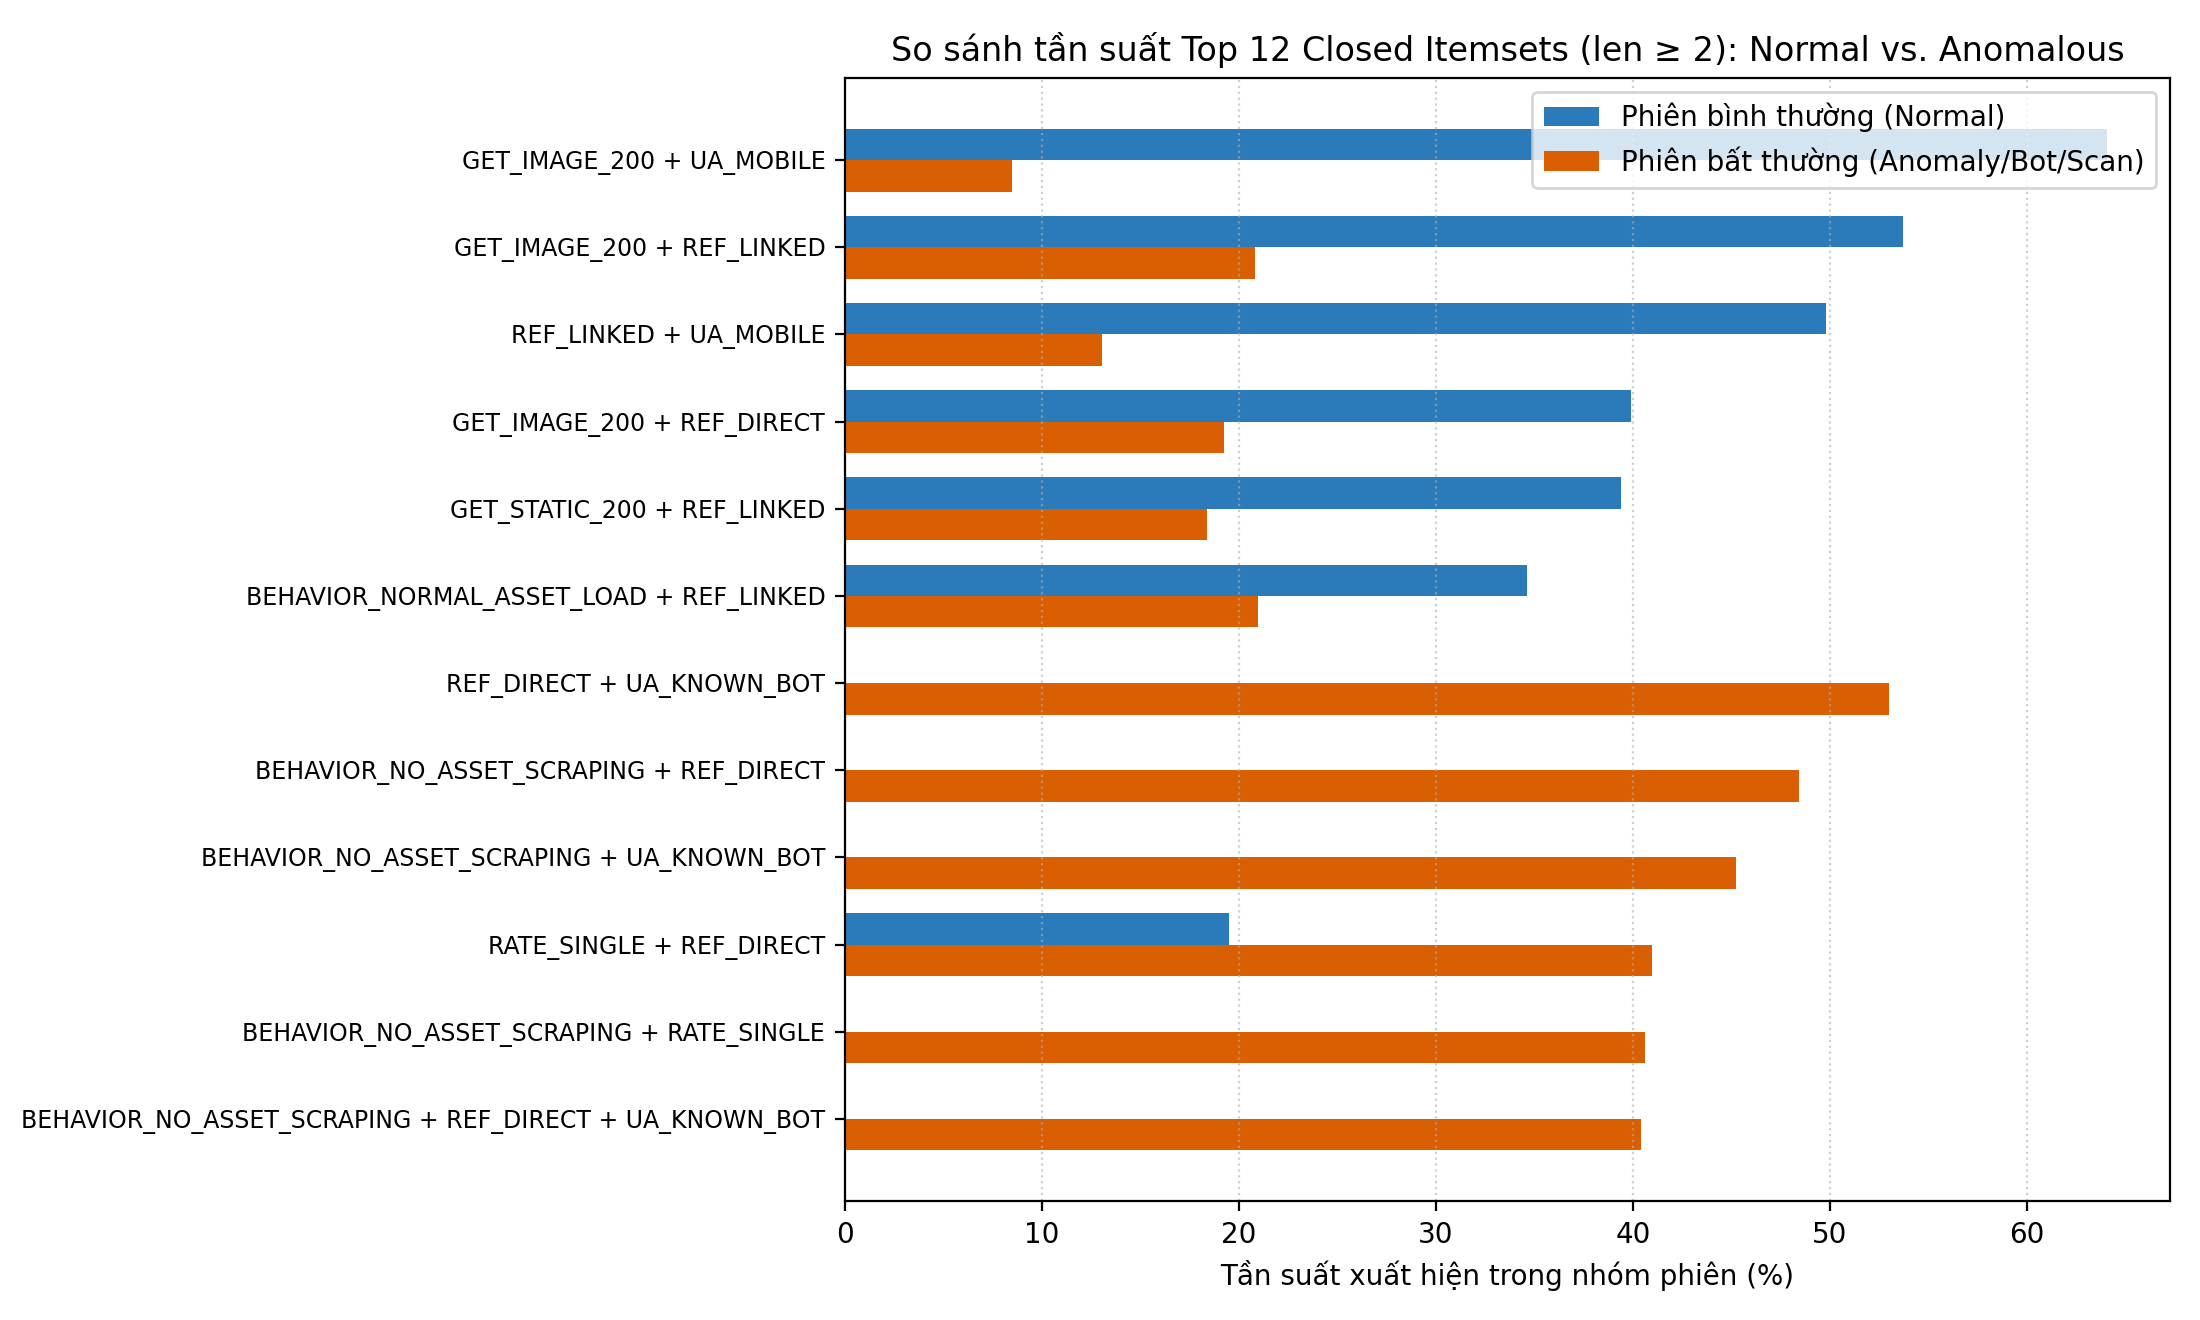

In [7]:
from IPython.display import Image, display

print("=== Bước 3.3: Phân tích & vẽ biểu đồ bằng scripts/analyze_web_logs.py ===")
res = run_cmd([sys.executable, "scripts/analyze_web_logs.py"], desc="analyze_web_logs.py")
print(res.stdout)

print("\n=== Bảng tổng hợp số lượng Closed Itemsets theo minsup ===")
display(pd.read_csv(WEB_OUT_DIR / "minsup_summary.csv"))

df_web_cmp = pd.read_csv(WEB_OUT_DIR / "normal_vs_anomaly_comparison.csv")
print("\n=== Top 10 Closed Itemsets đặc trưng mạnh cho phiên Bất thường / Bot / Scan (Ratio >= 1.5) ===")
df_anom_top = (
    df_web_cmp[df_web_cmp["anom_to_norm_ratio"] >= 1.5]
    .sort_values(["sup_anomaly_pct", "anom_to_norm_ratio"], ascending=[False, False])
    [["length", "sup_all_pct", "sup_normal_pct", "sup_anomaly_pct", "anom_to_norm_ratio", "event_templates"]]
    .head(10)
)
display(df_anom_top)

for fig_name in ["fig1_minsup_vs_itemsets.png", "fig2_normal_vs_anomaly.png"]:
    fig_path = WEB_OUT_DIR / "figures" / fig_name
    assert fig_path.exists(), f"Không tìm thấy hình kết quả: {fig_path}"
    print(f"\n--- {fig_name} ---")
    display(Image(filename=str(fig_path), width=820))

### Diễn giải nhanh kết quả Ứng dụng 1 (Web Server Access Logs)
- **Độ nhạy ngưỡng `minsup`:** Khi hạ `minsup` từ `10%` xuống `0,5%`, tổng số tập mục đóng tăng phi tuyến **43,8 lần** (từ **179** lên **7.839** tập đóng) và độ dài cực đại tăng gấp đôi (từ **6** lên **12** sự kiện đồng xuất hiện).
- **Tách biệt rõ rệt hành vi người dùng thật và Bot/Scraper:**
  - *Phiên bình thường (Normal):* Chiếm ưu thế ở các tổ hợp tải đầy đủ tài nguyên đi kèm điều hướng và trình duyệt di động (`GET_IMAGE_200 + UA_MOBILE`, `REF_LINKED + UA_MOBILE`).
  - *Phiên bất thường (Anomalous):* Nổi bật với các chữ ký bot/scraper gần như chỉ xuất hiện ở nhóm bất thường (`Normal = 0%`) như `REF_DIRECT + UA_KNOWN_BOT`, `BEHAVIOR_NO_ASSET_SCRAPING + REF_DIRECT` và `BEHAVIOR_NO_ASSET_SCRAPING + REF_DIRECT + UA_KNOWN_BOT`.
- **Hạn chế:** Tập log thô không có nhãn ground-truth nên việc gán nhãn dựa trên heuristic; đồng thời mô hình tập mục đóng bỏ qua thứ tự thời gian giữa các request trong cùng cửa sổ 5 phút.

---
## Phần 4. Ứng dụng 2: Khai phá mẫu trực quan (Visual Words) trên tập ảnh Caltech-101

### Quy trình gọi trực tiếp các script trong repo
1. `python scripts/analyze_caltech101.py --split-classes`: Tách `transactions.txt` (600 ảnh, 300 visual words từ RootSIFT + K-Means `SEED = 0`) thành 3 tệp giao dịch theo từng lớp (`airplanes`, `faces_easy`, `motorbikes`).
2. `julia --project=. src/main.jl -a optimized`: Khai phá Closed Itemsets cho toàn tập `all` (`minsup ∈ {0.10, 0.07, 0.05, 0.03}`) và từng lớp (`minsup ∈ {0.15, 0.10, 0.08}`).
3. `python scripts/analyze_caltech101.py`: Tính độ tinh khiết theo lớp (**Class Purity**), xuất các bảng CSV và vẽ biểu đồ `minsup` + 4 lưới patch `3×3` đại diện.

In [8]:
CALTECH_OUT_DIR = Path("results/application/cal_tech_101")
CALTECH_OUT_DIR.mkdir(parents=True, exist_ok=True)

# 1. Tách giao dịch theo từng lớp bằng scripts/analyze_caltech101.py --split-classes
print("=== Bước 4.1: Tách file giao dịch theo từng lớp ===")
res_split = run_cmd(
    [sys.executable, "scripts/analyze_caltech101.py", "--split-classes"],
    desc="analyze_caltech101.py --split-classes",
)
print(res_split.stdout)

# 2. Chạy CHARM tối ưu (src/main.jl) trên phạm vi toàn bộ (all) và 3 lớp riêng
RUN_PLAN = [
    ("all", CALTECH_PRE_DIR / "transactions.txt", ["0.10", "0.07", "0.05", "0.03"]),
    ("airplanes", CALTECH_PRE_DIR / "transactions_airplanes.txt", ["0.15", "0.10", "0.08"]),
    ("faces_easy", CALTECH_PRE_DIR / "transactions_faces_easy.txt", ["0.15", "0.10", "0.08"]),
    ("motorbikes", CALTECH_PRE_DIR / "transactions_motorbikes.txt", ["0.15", "0.10", "0.08"]),
]

print("=== Bước 4.2: Chạy CHARM tối ưu (src/main.jl) trên Caltech-101 ===")
for scope, tx_file, minsups in RUN_PLAN:
    for ms in minsups:
        out_file = CALTECH_OUT_DIR / f"charm_{scope}_minsup_{ms}.txt"
        res = run_cmd(
            [
                "julia", "--project=.", "src/main.jl",
                "-i", str(tx_file),
                "-m", ms,
                "-o", str(out_file),
                "-a", "optimized",
            ],
            desc=f"CHARM Caltech {scope} minsup={ms}",
        )
        print(" ", res.stdout.strip())

=== Bước 4.1: Tách file giao dịch theo từng lớp ===
[OK] analyze_caltech101.py --split-classes (1.34s)
[DONE] Đã xuất 200 giao dịch lớp 'airplanes' -> data/application/cal_tech_101/pre_process/transactions_airplanes.txt
[DONE] Đã xuất 200 giao dịch lớp 'motorbikes' -> data/application/cal_tech_101/pre_process/transactions_motorbikes.txt
[DONE] Đã xuất 200 giao dịch lớp 'faces_easy' -> data/application/cal_tech_101/pre_process/transactions_faces_easy.txt

=== Bước 4.2: Chạy CHARM tối ưu (src/main.jl) trên Caltech-101 ===
[OK] CHARM Caltech all minsup=0.10 (3.02s)
  [OptimizedCharmSolver] Transactions: 600 | MinSup Count: 60 | Closed Itemsets: 294 | Read: 18.74 ms | Time: 5.63 ms | Write: 11.6 ms | Total: 35.97 ms | PeakRSS: 338.8 MB
[OK] CHARM Caltech all minsup=0.07 (3.03s)
  [OptimizedCharmSolver] Transactions: 600 | MinSup Count: 43 | Closed Itemsets: 371 | Read: 19.5 ms | Time: 6.72 ms | Write: 13.22 ms | Total: 39.44 ms | PeakRSS: 339.0 MB
[OK] CHARM Caltech all minsup=0.05 (5.36s)

In [9]:
print("=== Bước 4.3: Phân tích Class Purity & vẽ lưới patch bằng scripts/analyze_caltech101.py ===")
res = run_cmd([sys.executable, "scripts/analyze_caltech101.py"], desc="analyze_caltech101.py")
print(res.stdout)

print("\n=== Bảng tổng hợp Closed Itemsets theo phạm vi và minsup ===")
display(pd.read_csv(CALTECH_OUT_DIR / "caltech_minsup_summary.csv"))

for scope in ["all", "airplanes", "faces_easy", "motorbikes"]:
    csv_path = CALTECH_OUT_DIR / f"top_visual_itemsets_{scope}.csv"
    assert csv_path.exists(), f"Không tìm thấy bảng kết quả: {csv_path}"
    print(f"\n=== Top 8 Closed Itemsets (len >= 2) — Phạm vi: {scope.upper()} ===")
    display(pd.read_csv(csv_path).head(8))

=== Bước 4.3: Phân tích Class Purity & vẽ lưới patch bằng scripts/analyze_caltech101.py ===
[OK] analyze_caltech101.py (9.13s)

=== 1. TỔNG HỢP KẾT QUẢ CHARM TRÊN CALTECH-101 ===
     scope  minsup  total_closed  closed_len_ge_2  max_length                             file
 airplanes    0.15           180               14           3  charm_airplanes_minsup_0.15.txt
 airplanes    0.10           479              248           3  charm_airplanes_minsup_0.10.txt
 airplanes    0.08          1117              865           4  charm_airplanes_minsup_0.08.txt
       all    0.10           294                3           2        charm_all_minsup_0.10.txt
       all    0.07           371               73           2        charm_all_minsup_0.07.txt
       all    0.05          1540             1240           3        charm_all_minsup_0.05.txt
       all    0.03         15845            15545           5        charm_all_minsup_0.03.txt
faces_easy    0.15           235               74           3

,scope,minsup,total_closed,closed_len_ge_2,max_length,file
0,airplanes,0.15,180,14,3,charm_airplanes_minsup_0.15.txt
1,airplanes,0.10,479,248,3,charm_airplanes_minsup_0.10.txt
2,airplanes,0.08,1117,865,4,charm_airplanes_minsup_0.08.txt
3,all,0.10,294,3,2,charm_all_minsup_0.10.txt
4,all,0.07,371,73,2,charm_all_minsup_0.07.txt
5,all,0.05,1540,1240,3,charm_all_minsup_0.05.txt
6,all,0.03,15845,15545,5,charm_all_minsup_0.03.txt
7,faces_easy,0.15,235,74,3,charm_faces_easy_minsup_0.15.txt
8,faces_easy,0.10,850,602,4,charm_faces_easy_minsup_0.10.txt
9,faces_easy,0.08,1830,1566,5,charm_faces_easy_minsup_0.08.txt



=== Top 8 Closed Itemsets (len >= 2) — Phạm vi: ALL ===


,word_ids,length,sup_in_scope,sup_in_scope_pct,total_all_600,airplanes_cnt,motorbikes_cnt,faces_easy_cnt,top_class,purity_pct
0,45 102,2,72,12.00,72,6,57,9,motorbikes,79.2
1,63 141,2,65,10.83,65,2,0,63,faces_easy,96.9
2,60 93,2,62,10.33,62,3,42,17,motorbikes,67.7
3,130 141,2,56,9.33,56,0,1,55,faces_easy,98.2
4,56 259,2,55,9.17,55,5,48,2,motorbikes,87.3
5,93 106,2,55,9.17,55,4,42,9,motorbikes,76.4
6,60 106,2,55,9.17,55,3,41,11,motorbikes,74.5
7,157 191,2,55,9.17,55,26,12,17,airplanes,47.3



=== Top 8 Closed Itemsets (len >= 2) — Phạm vi: AIRPLANES ===


,word_ids,length,sup_in_scope,sup_in_scope_pct,total_all_600,airplanes_cnt,motorbikes_cnt,faces_easy_cnt,top_class,purity_pct
0,14 200,2,43,21.5,49,43,4,2,airplanes,87.8
1,14 239,2,40,20.0,46,40,4,2,airplanes,87.0
2,5 200,2,38,19.0,41,38,3,0,airplanes,92.7
3,200 239,2,36,18.0,40,36,3,1,airplanes,90.0
4,200 268,2,34,17.0,37,34,2,1,airplanes,91.9
5,5 268,2,31,15.5,31,31,0,0,airplanes,100.0
6,14 200 239,3,31,15.5,34,31,2,1,airplanes,91.2
7,5 14,2,31,15.5,37,31,4,2,airplanes,83.8



=== Top 8 Closed Itemsets (len >= 2) — Phạm vi: FACES_EASY ===


,word_ids,length,sup_in_scope,sup_in_scope_pct,total_all_600,airplanes_cnt,motorbikes_cnt,faces_easy_cnt,top_class,purity_pct
0,63 141,2,63,31.5,65,2,0,63,faces_easy,96.9
1,130 141,2,55,27.5,56,0,1,55,faces_easy,98.2
2,13 215,2,52,26.0,52,0,0,52,faces_easy,100.0
3,97 141,2,47,23.5,47,0,0,47,faces_easy,100.0
4,46 97,2,45,22.5,46,0,1,45,faces_easy,97.8
5,136 141,2,44,22.0,45,0,1,44,faces_easy,97.8
6,85 215,2,44,22.0,46,0,2,44,faces_easy,95.7
7,13 85,2,42,21.0,42,0,0,42,faces_easy,100.0



=== Top 8 Closed Itemsets (len >= 2) — Phạm vi: MOTORBIKES ===


,word_ids,length,sup_in_scope,sup_in_scope_pct,total_all_600,airplanes_cnt,motorbikes_cnt,faces_easy_cnt,top_class,purity_pct
0,45 102,2,57,28.5,72,6,57,9,motorbikes,79.2
1,56 259,2,48,24.0,55,5,48,2,motorbikes,87.3
2,93 106,2,42,21.0,55,4,42,9,motorbikes,76.4
3,60 93,2,42,21.0,62,3,42,17,motorbikes,67.7
4,60 106,2,41,20.5,55,3,41,11,motorbikes,74.5
5,45 56,2,40,20.0,43,1,40,2,motorbikes,93.0
6,45 259,2,39,19.5,44,4,39,1,motorbikes,88.6
7,45 70,2,38,19.0,43,3,38,2,motorbikes,88.4



--- Biểu đồ ảnh hưởng của minsup lên số lượng Closed Itemsets (len >= 2) (fig1_caltech_minsup_curve.png) ---


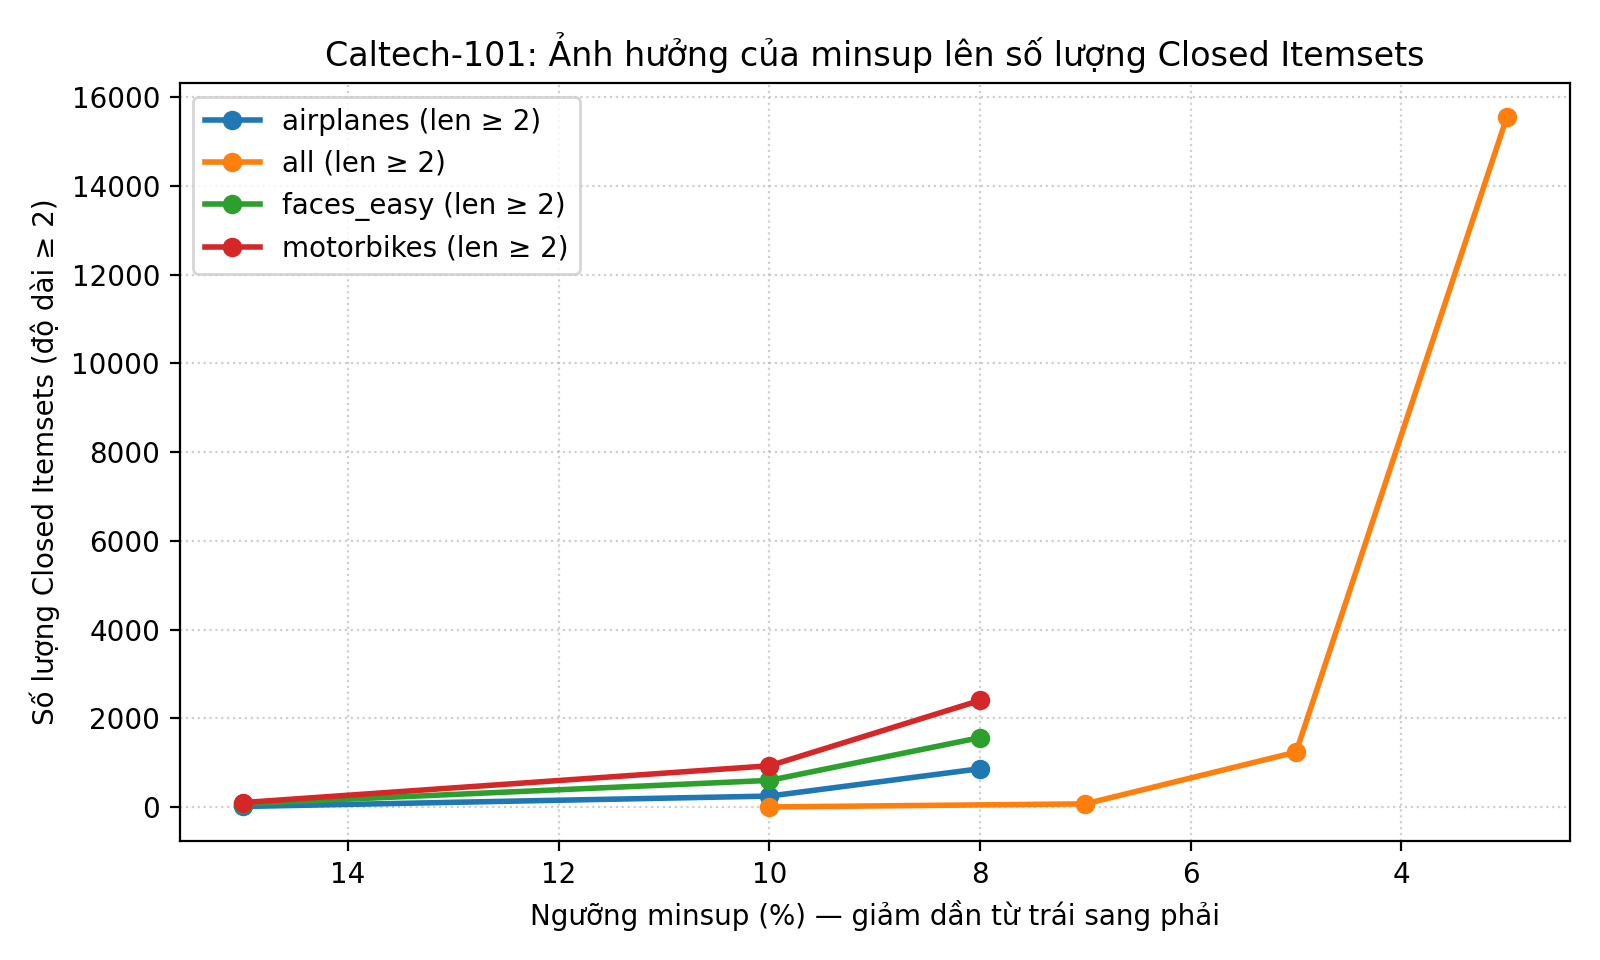


--- Lưới patch 3×3 — Top 5 Closed Itemsets trên toàn bộ 600 ảnh (all, minsup=0.03) (fig_patches_all.png) ---


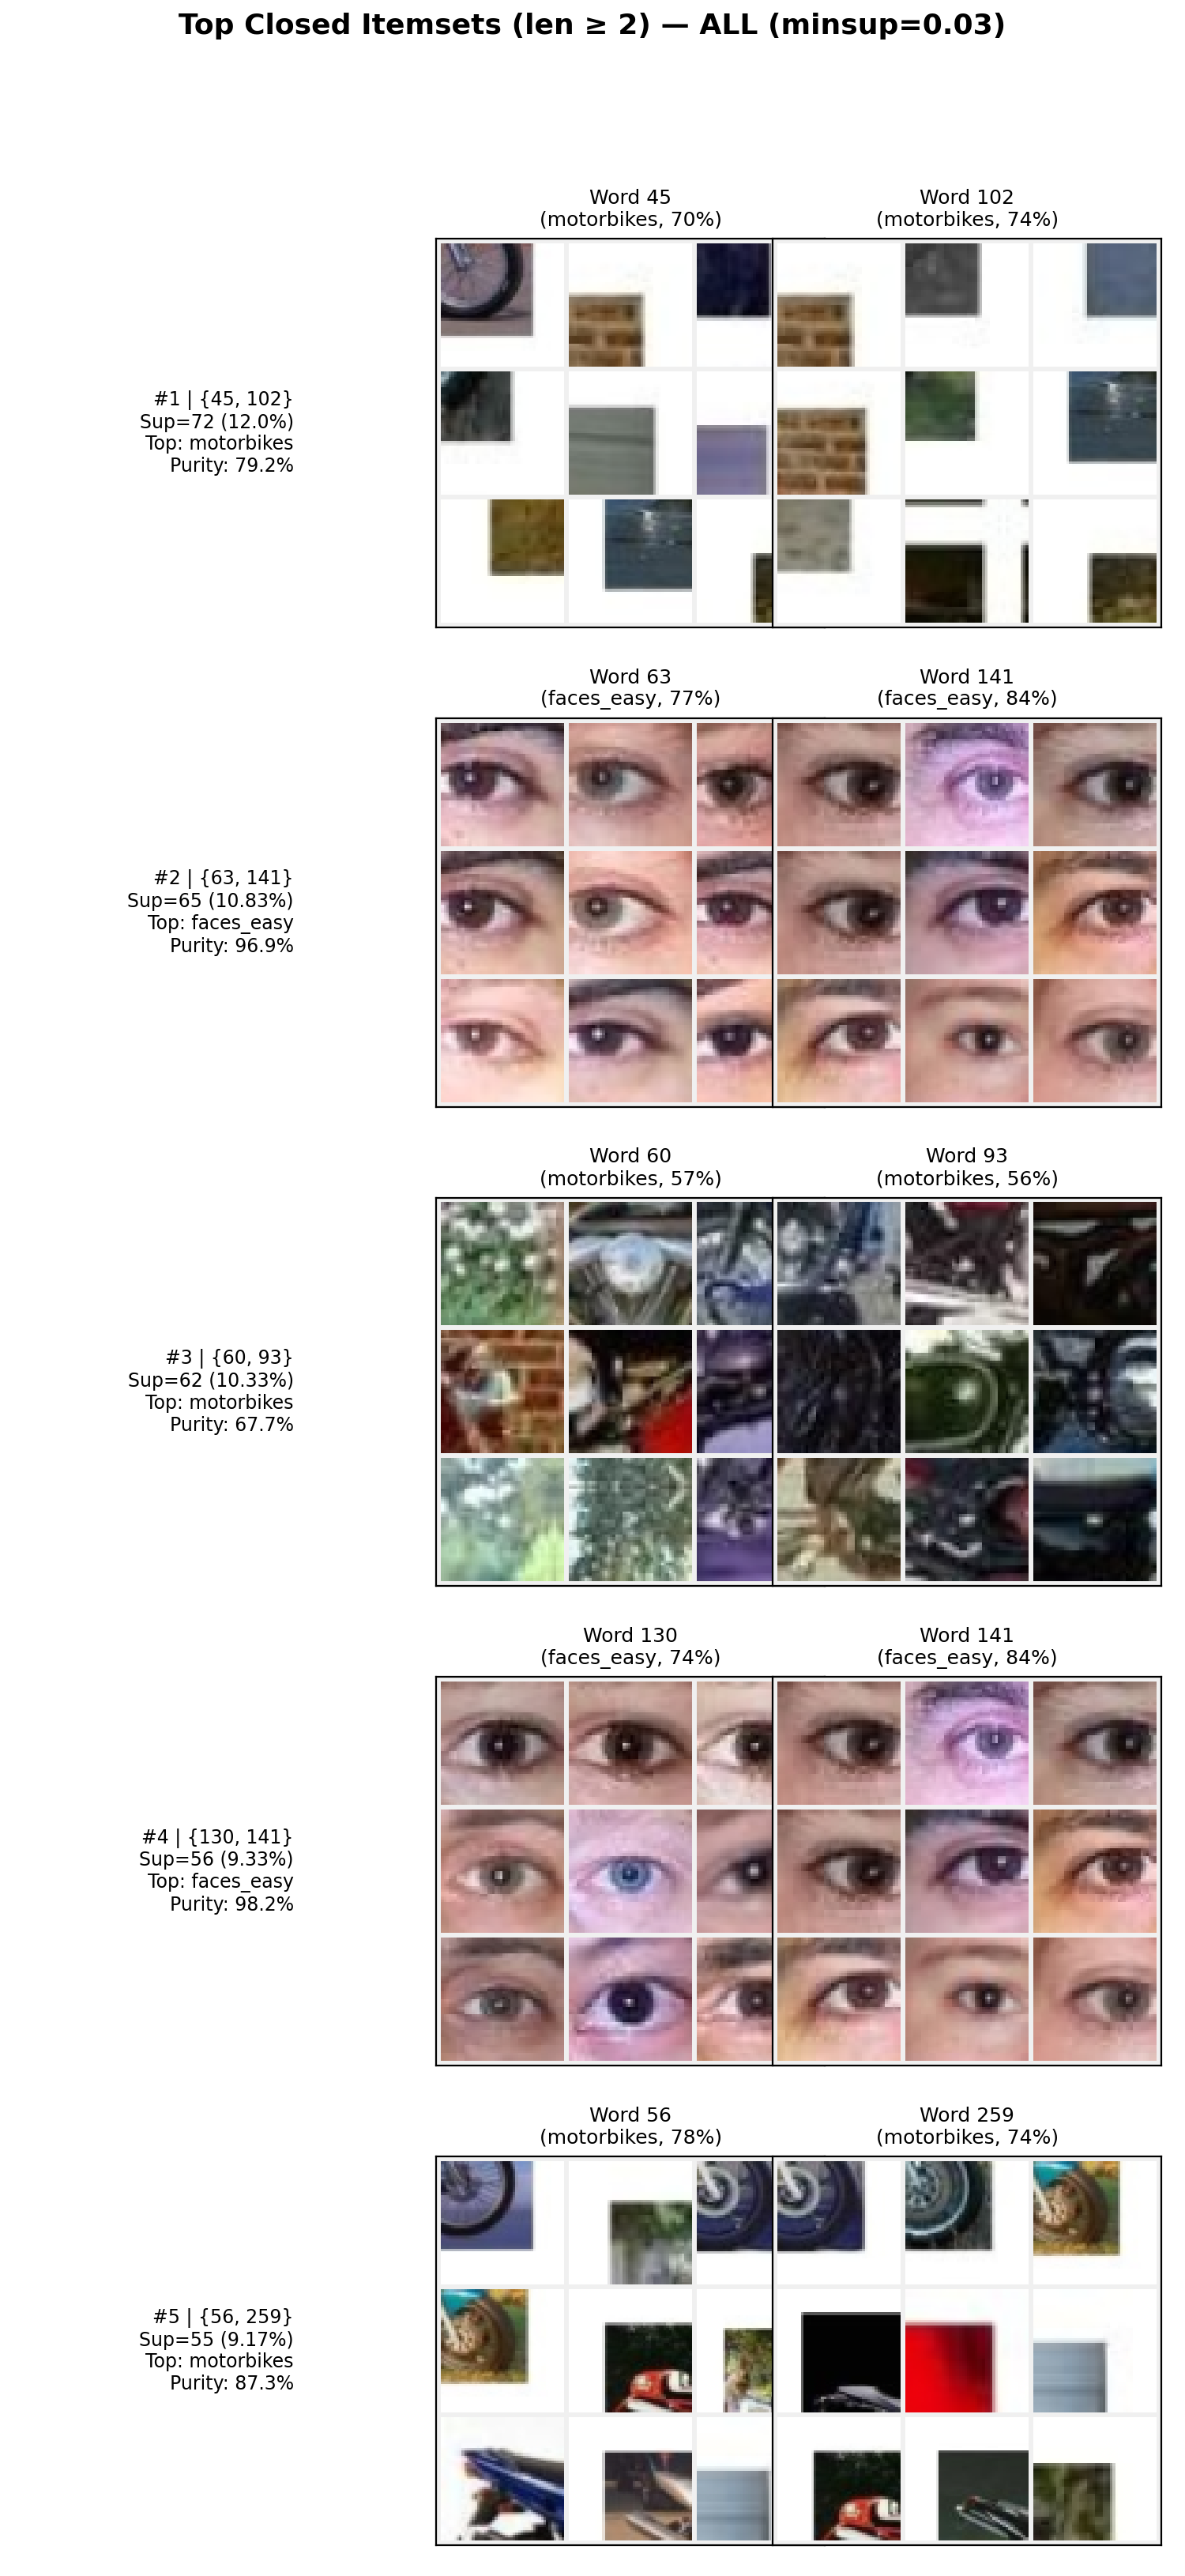


--- Lưới patch 3×3 — Top 5 Closed Itemsets lớp AIRPLANES (minsup=0.08) (fig_patches_airplanes.png) ---


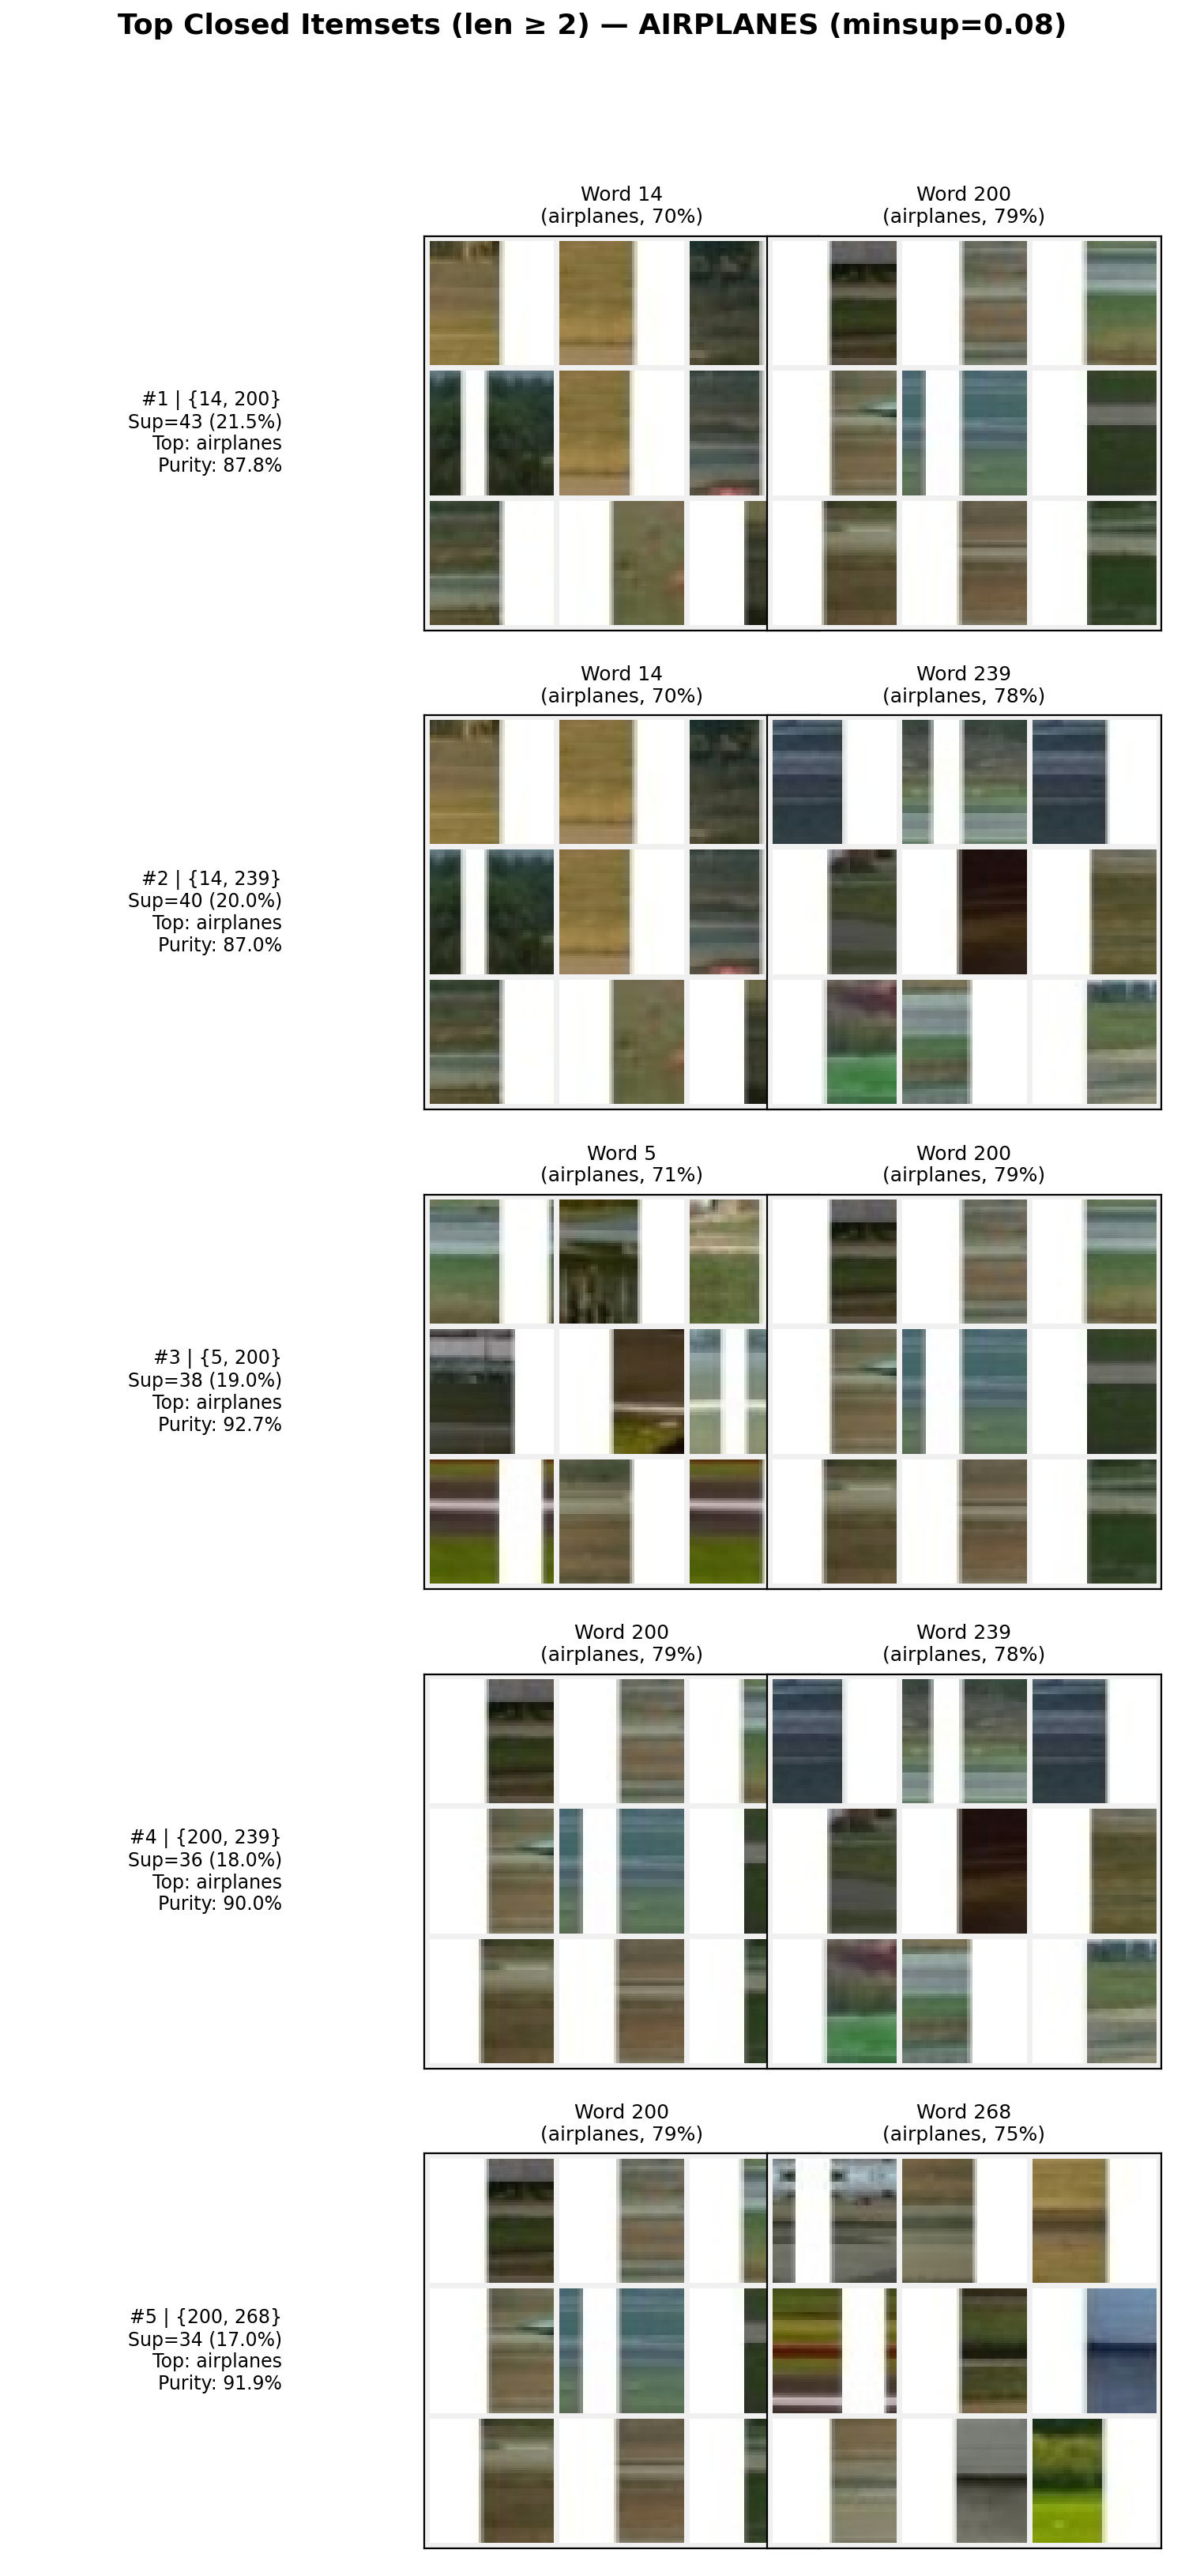


--- Lưới patch 3×3 — Top 5 Closed Itemsets lớp FACES_EASY (minsup=0.08) (fig_patches_faces_easy.png) ---


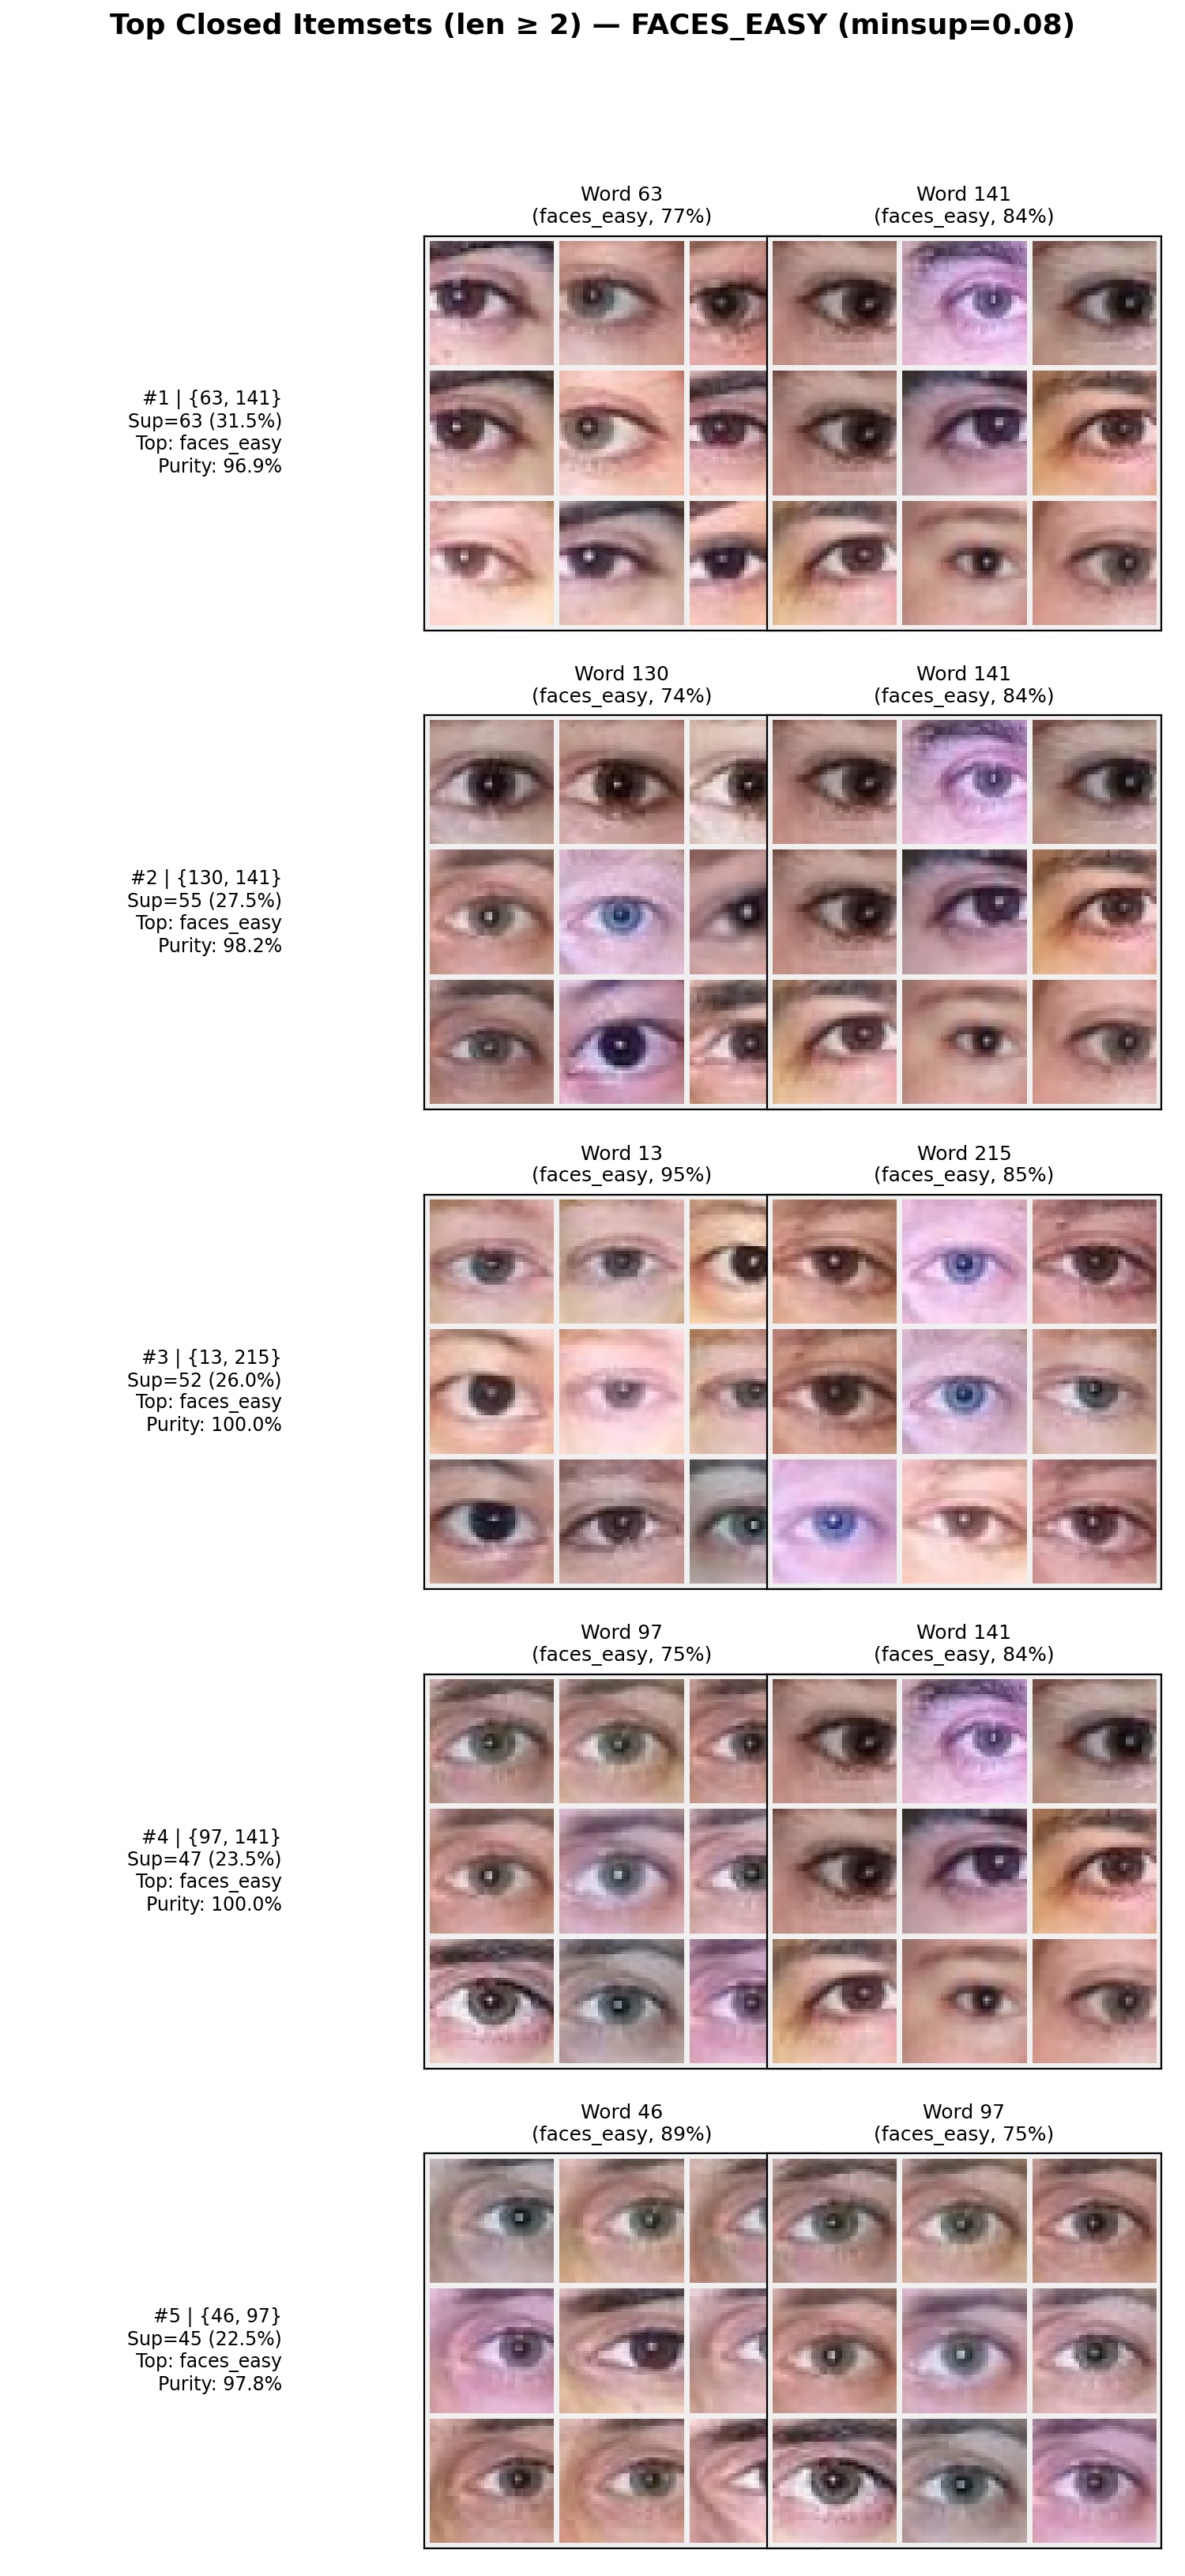


--- Lưới patch 3×3 — Top 5 Closed Itemsets lớp MOTORBIKES (minsup=0.08) (fig_patches_motorbikes.png) ---


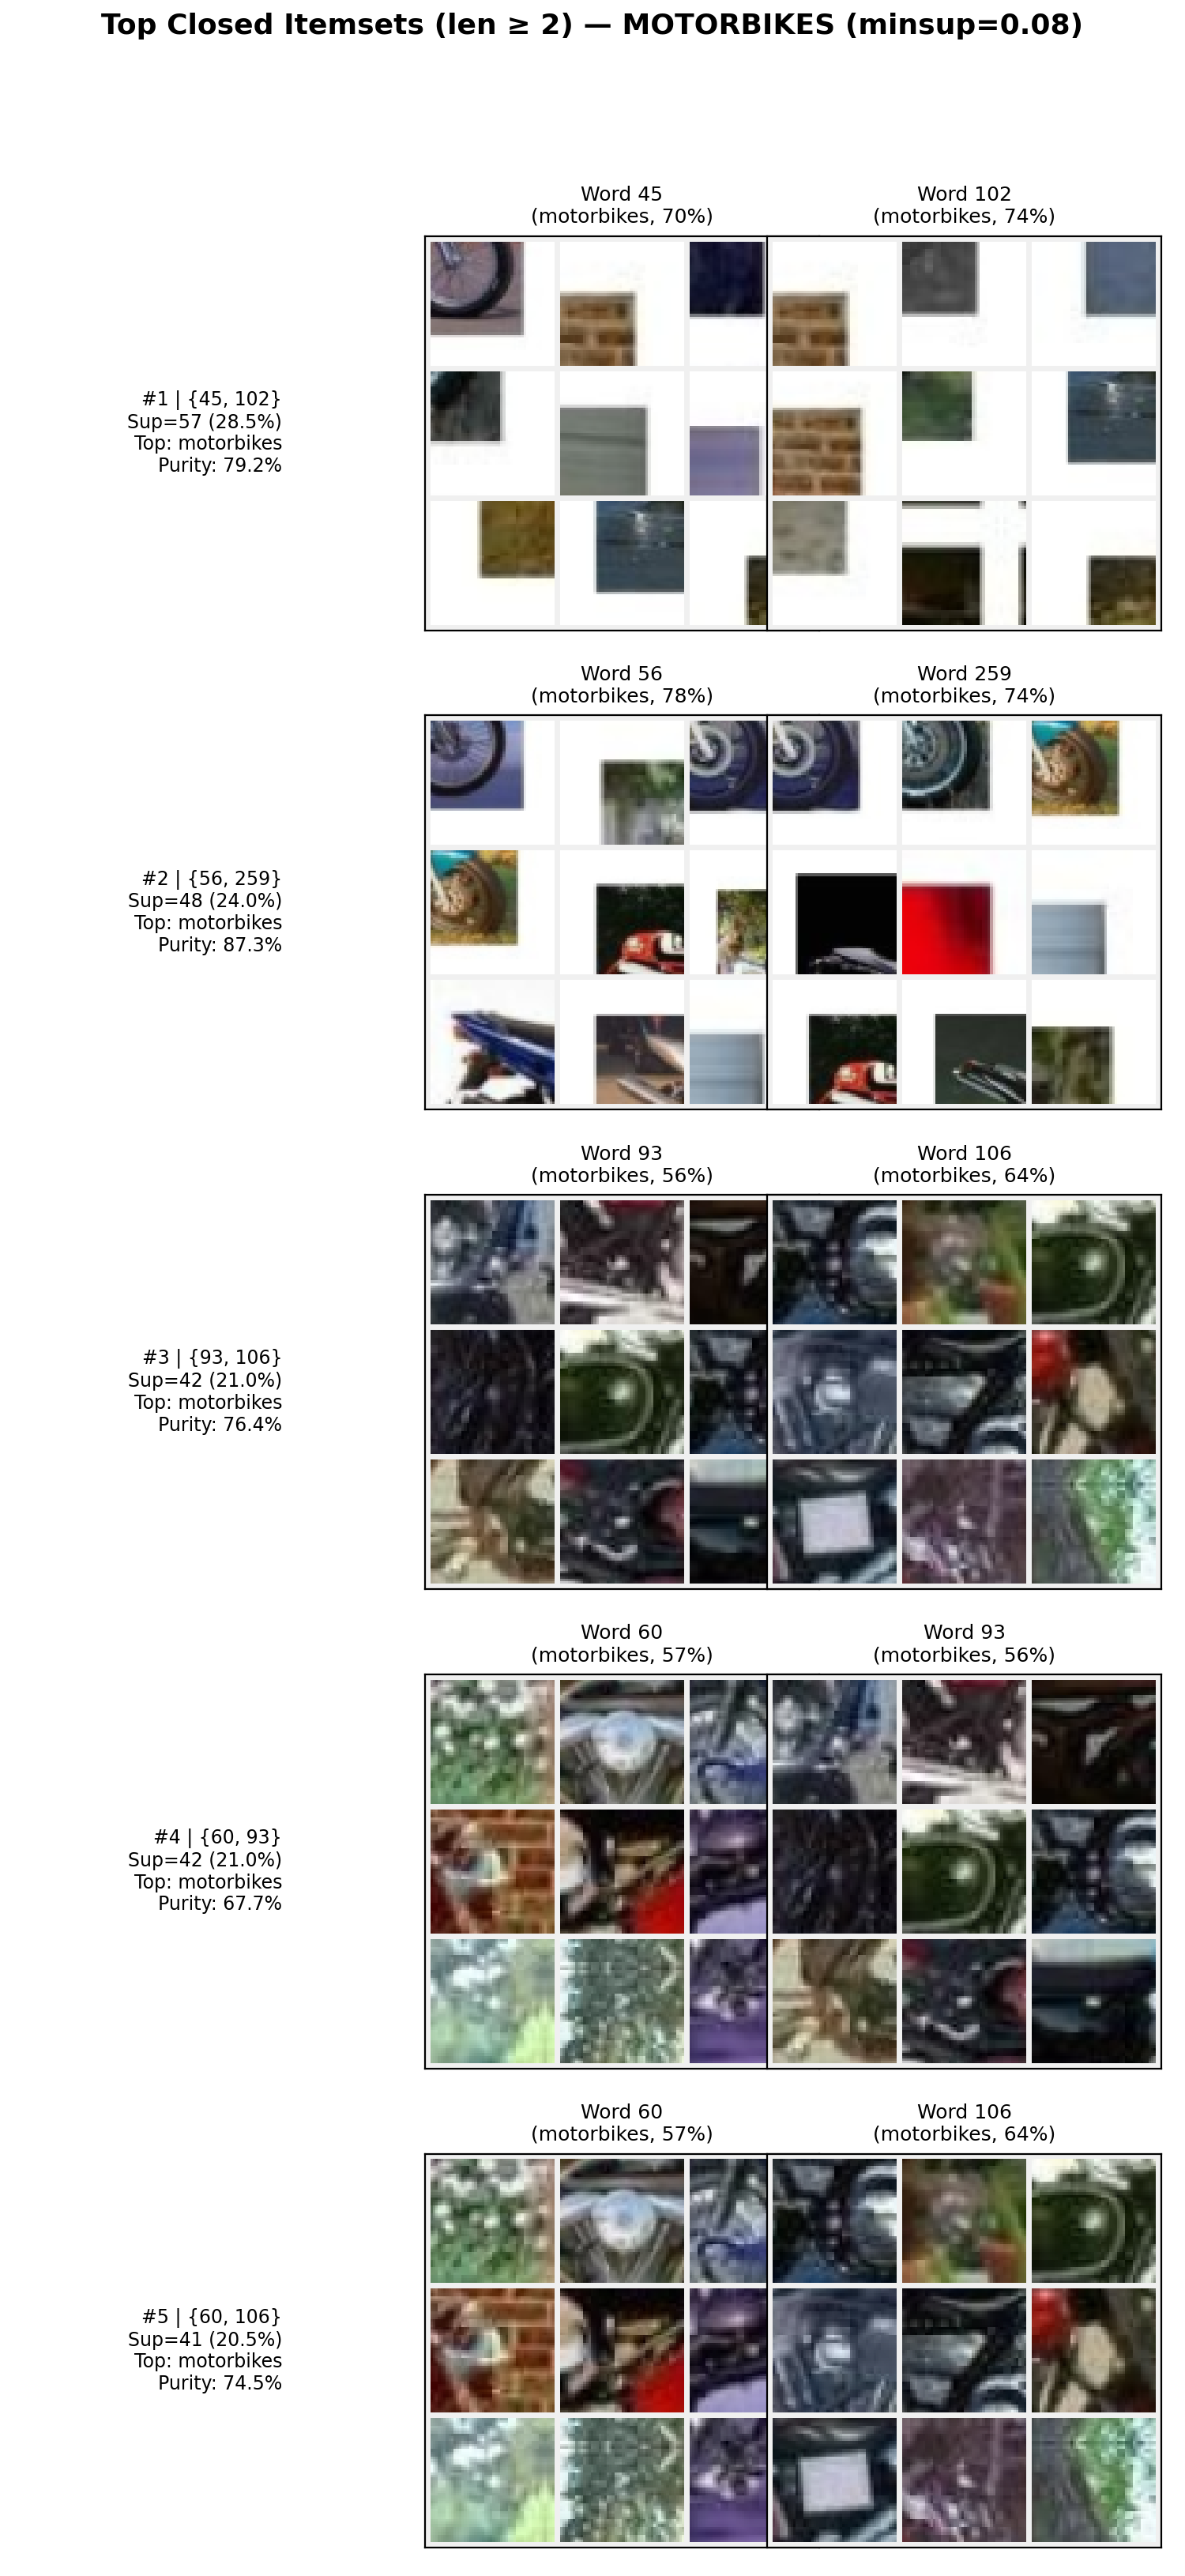

In [10]:
caltech_figs = [
    ("fig1_caltech_minsup_curve.png", "Biểu đồ ảnh hưởng của minsup lên số lượng Closed Itemsets (len >= 2)"),
    ("fig_patches_all.png", "Lưới patch 3×3 — Top 5 Closed Itemsets trên toàn bộ 600 ảnh (all, minsup=0.03)"),
    ("fig_patches_airplanes.png", "Lưới patch 3×3 — Top 5 Closed Itemsets lớp AIRPLANES (minsup=0.08)"),
    ("fig_patches_faces_easy.png", "Lưới patch 3×3 — Top 5 Closed Itemsets lớp FACES_EASY (minsup=0.08)"),
    ("fig_patches_motorbikes.png", "Lưới patch 3×3 — Top 5 Closed Itemsets lớp MOTORBIKES (minsup=0.08)"),
]

for fname, caption in caltech_figs:
    fpath = CALTECH_OUT_DIR / "figures" / fname
    assert fpath.exists(), f"Không tìm thấy hình kết quả: {fpath}"
    print(f"\n--- {caption} ({fname}) ---")
    display(Image(filename=str(fpath), width=850))

### Diễn giải nhanh kết quả Ứng dụng 2 (Caltech-101 Visual Patterns)
- **Bùng nổ tổ hợp & khác biệt nội lớp:** Trên toàn tập `all`, hạ `minsup` từ `10%` xuống `3%` khiến số closed itemset (`len ≥ 2`) tăng từ **3** lên **15.545** (gấp >5.181 lần) do độ dày ma trận đạt `15,97%`. Ở `minsup = 8%` theo lớp, `motorbikes` sinh nhiều tập đóng nhất (**2.405**), tiếp đến `faces_easy` (**1.566**) và `airplanes` (**865**).
- **Quy luật Độ dài – Độ tinh khiết (Length–Purity Trade-off):** Các tổ hợp độ dài 4–5 như `{26, 45, 56, 102, 259}` (`motorbikes`), `{46, 97, 141, 167, 242}` (`faces_easy`) và `{5, 14, 200, 239}` (`airplanes`) đạt độ tinh khiết tuyệt đối **100,0%**, đóng vai trò đặc trưng bậc trung (*visual phrases*) hữu ích cho **Phân loại ảnh** và **Truy vấn ảnh (CBIR)**.
- **Ảnh hưởng tham số `k` và hạn chế:** `k = 300` giữ cân bằng giữa lượng tử hóa thô (`k` nhỏ) và phân mảnh (`k` lớn). Hạn chế chính là bỏ qua vị trí không gian tương đối giữa các patch và nhạy cảm với nhiễu nền chung (như `{157, 191}`, purity **47,3%**).

---
## Phần 5. Kiểm tra tổng hợp đầu ra (Reproducibility Checklist)

Xác nhận toàn bộ 14 tệp kết quả (`.csv` và `.png`) của cả hai ứng dụng đã được tạo đầy đủ và khác rỗng.

In [11]:
expected_outputs = [
    WEB_OUT_DIR / "minsup_summary.csv",
    WEB_OUT_DIR / "normal_vs_anomaly_comparison.csv",
    WEB_OUT_DIR / "figures" / "fig1_minsup_vs_itemsets.png",
    WEB_OUT_DIR / "figures" / "fig2_normal_vs_anomaly.png",
    CALTECH_OUT_DIR / "caltech_minsup_summary.csv",
    CALTECH_OUT_DIR / "top_visual_itemsets_all.csv",
    CALTECH_OUT_DIR / "top_visual_itemsets_airplanes.csv",
    CALTECH_OUT_DIR / "top_visual_itemsets_faces_easy.csv",
    CALTECH_OUT_DIR / "top_visual_itemsets_motorbikes.csv",
    CALTECH_OUT_DIR / "figures" / "fig1_caltech_minsup_curve.png",
    CALTECH_OUT_DIR / "figures" / "fig_patches_all.png",
    CALTECH_OUT_DIR / "figures" / "fig_patches_airplanes.png",
    CALTECH_OUT_DIR / "figures" / "fig_patches_faces_easy.png",
    CALTECH_OUT_DIR / "figures" / "fig_patches_motorbikes.png",
]

rows = []
missing = []
for p in expected_outputs:
    exists = p.exists() and p.stat().st_size > 0
    if not exists:
        missing.append(str(p))
    rows.append({
        "Tệp kết quả": str(p),
        "Trạng thái": "OK" if exists else "THIẾU",
        "Kích thước (KB)": round(p.stat().st_size / 1024.0, 1) if exists else 0.0,
    })

display(pd.DataFrame(rows))
if missing:
    raise FileNotFoundError(f"Thiếu {len(missing)} tệp kết quả: {missing}")
print("\n[SUCCESS] Toàn bộ pipeline Demo Chương 3 (2 ứng dụng) đã chạy sạch và tái lập đầy đủ!")

,Tệp kết quả,Trạng thái,Kích thước (KB)
0,results/application/web_server_access_logs/min...,OK,0.3
1,results/application/web_server_access_logs/nor...,OK,4.2
2,results/application/web_server_access_logs/fig...,OK,118.6
3,results/application/web_server_access_logs/fig...,OK,181.0
4,results/application/cal_tech_101/caltech_minsu...,OK,0.8
5,results/application/cal_tech_101/top_visual_it...,OK,647.0
6,results/application/cal_tech_101/top_visual_it...,OK,35.7
7,results/application/cal_tech_101/top_visual_it...,OK,67.3
8,results/application/cal_tech_101/top_visual_it...,OK,101.4
9,results/application/cal_tech_101/figures/fig1_...,OK,140.0



[SUCCESS] Toàn bộ pipeline Demo Chương 3 (2 ứng dụng) đã chạy sạch và tái lập đầy đủ!
